# Betting Against Beta — Section 4 (One Choice, Changed) and Section 5 (Risk)

**Data.** CRSP monthly common stocks on NYSE, AMEX and Nasdaq, 1963-01 to 2026-09, and Ken French's `Mkt-RF` and `RF`, read from `Project_Beta/data/`. We use the supplied **delisting-adjusted returns** (`ret`). Excess returns subtract `RF`; the market is `Mkt-RF`.

**Conventions.** These are the same as in Part B (`B_sections2_3.ipynb`), and the shared code is in `bab_core.py`. A portfolio formed at month end *t* uses data through *t*, earns the return of *t+1*, and uses market cap at *t*. Members at *t* need a beta, positive market cap, a price, and no delisting code at *t*. Any extra screen is applied at *t*. A held stock with a missing return in *t+1* earns a total return of zero (excess −RF) and keeps its weight. Betas omit months with a missing return. Means are annualized ×12 and volatilities ×√12. Sharpe ratios use excess returns, with standard error $\sqrt{(1+SR^2/24)/N}$ for *N* years. Alpha and beta come from OLS on `Mkt-RF`; alpha is annualized ×12, and **every t-statistic is the plain OLS t-statistic**. The book's return is a self-financing excess return, and **drawdowns are measured on the compounded path of that excess return**. Sections 4 and 5 ignore transaction costs, financing and borrow fees. **Every full-sample exhibit runs from 1966-01 to 2026-09** (the first 60-month betas, at their 36-month minimum, exist at the end of 1965). "From 2014" means 2014-01 to 2026-09, twelve years and nine months.

New helpers are in `bab_extra.py`. `bab_core.py` is unchanged.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import bab_core as bc
import bab_extra as bx

panel = bx.load_panel()                               # bab_core.load_panel on Project_Beta/data
mkt = panel.mkt
beta60 = bc.rolling_beta(panel.ex, mkt, 60, 36)       # trailing 60 months, at least 36
combined = bc.shrink(beta60, 0.6)                     # 0.6 * beta + 0.4
print(f"{panel.ret.shape[0]} months x {panel.ret.shape[1]:,} permnos, "
      f"{panel.ret.index[0]:%Y-%m} to {panel.ret.index[-1]:%Y-%m}")

FULL = "1966-01 to 2026-09"
POST = "2014-01 to 2026-09"


def show(df, pct=(), precision=3):
    display(df.style.format({c: "{:.2%}" for c in pct}, precision=precision))

765 months x 26,519 permnos, 1963-01 to 2026-09


## Default book: rebuild and regression check

The default book is rebuilt with `bc.build_book(combined, panel)`. Before building anything on top of it, the table below checks it against the numbers reported in Part B.

In [2]:
book_def, w_def = bc.build_book(combined, panel, return_weights=True)
m_def = mkt.reindex(book_def.index)


def realized_beta(x, start=None):
    x = x.loc[start:]
    return bc.ols(x, mkt.reindex(x.index))[1]


p_def = bc.performance(book_def["book"], mkt)
rebuilt = {
    "holding months": len(book_def),
    "failures": int(book_def["failed"].sum()),
    "long: avg ex-ante beta": book_def["beta_L"].mean(),
    "long: realized beta": realized_beta(book_def["r_L"]),
    "long: avg leverage": book_def["lev_L"].mean(),
    "short: avg ex-ante beta": book_def["beta_H"].mean(),
    "short: realized beta": realized_beta(book_def["r_H"]),
    "short: avg leverage": book_def["lev_H"].mean(),
    "book: realized beta": p_def["beta"],
    "book: realized beta from 2014": realized_beta(book_def["book"], "2014-01"),
    "book: alpha (ann.)": p_def["alpha"],
    "book: mean excess (ann.)": p_def["mean"],
    "turnover / month": book_def["turnover"].mean(),
    "turnover / month from 2014": book_def.loc["2014":, "turnover"].mean(),
    "long below NYSE p20": book_def["small_L"].mean(),
    "short below NYSE p20": book_def["small_H"].mean(),
    "long below NYSE p20 from 2014": book_def.loc["2014":, "small_L"].mean(),
    "short below NYSE p20 from 2014": book_def.loc["2014":, "small_H"].mean(),
    "long price < $5": book_def["penny_L"].mean(),
    "short price < $5": book_def["penny_H"].mean(),
}
target = [729, 0, 0.66, 0.77, 1.56, 1.57, 1.49, 0.64, 0.20, 0.30, 0.074, 0.088,
          0.35, 0.34, 0.59, 0.56, 0.54, 0.47, 0.20, 0.30]
check = pd.DataFrame({"Part B": target, "rebuilt": list(rebuilt.values())}, index=list(rebuilt))
# Part B reports two decimals; the two penny shares are given only as "about 20%" and "nearly 30%"
tol = pd.Series(0.006, index=check.index)
tol[["long price < $5", "short price < $5"]] = 0.015
check["match"] = (check["Part B"] - check["rebuilt"]).abs() <= tol
print(f"Default book, holding months {book_def.index[0]:%Y-%m} to {book_def.index[-1]:%Y-%m}")
show(check, precision=3)

Default book, holding months 1966-01 to 2026-09


,Part B,rebuilt,match
holding months,729.000,729.000,True
failures,0.000,0.000,True
long: avg ex-ante beta,0.660,0.663,True
long: realized beta,0.770,0.769,True
long: avg leverage,1.560,1.563,True
short: avg ex-ante beta,1.570,1.570,True
short: realized beta,1.490,1.489,True
short: avg leverage,0.640,0.641,True
book: realized beta,0.200,0.196,True
book: realized beta from 2014,0.300,0.297,True


The rebuilt default book reproduces Part B to two decimals on every reported number. The penny shares are checked loosely because Part B gives them only in words ("about 20%" long, "nearly 30%" short).

## 4. One Choice, Changed

### 4.1 Pre-registration

**Mechanism.** Exclusions: a size screen.

**Alternative (one book).** At each formation date *t*, remove every stock whose market cap at *t* is below the 20th percentile of market cap among NYSE stocks at *t*. Stocks at or above the breakpoint stay, whatever their exchange. The rule uses only data dated *t*. The remaining stocks are then ranked, split and weighted within the screened cross section.

**What stays fixed (identical to the default book).** The panel, the delisting-adjusted returns and the membership rule (beta, positive cap, a price, no `dlstcd` at *t*). The trailing 60-month beta (at least 36 months) on monthly excess returns, combined as 0.6·β̂ + 0.4, used both to sort and to set leverage. The median split, with the middle stock long when the count is odd. Rank weights ∝ |z − z̄|, with *z* the rank in the (screened) cross section. Leverage L_L = 1/β_L and L_H = 1/β_H from each leg's weighted-average combined beta. Cash 1 − L_L + L_H at the bill rate. One-month holding. The missing-return convention. The failure rule. The sample 1966-01 to 2026-09. No costs.

**Expectation (a prediction, not a result).** We expect dropping stocks below the NYSE 20th percentile to lower the book's alpha and Sharpe ratio, but leave alpha positive with t > 2, and to cut turnover, because part of the default premium comes from small, illiquid stocks whose betas are measured with the most error.

### 4.2 The screened book against the default

The screened book is `bc.build_book(combined, panel, screen=bx.size_screen(panel, 20))`, where `size_screen` is True when the market cap at *t* is at or above the NYSE 20th percentile at *t*. Every other argument is the same as for the default book.

In [3]:
screen20 = bx.size_screen(panel, 20)
book_scr, w_scr = bc.build_book(combined, panel, screen=screen20, return_weights=True)
books = {"default": book_def, "screened (NYSE p20)": book_scr}

for name, b in books.items():
    fails = b[b["failed"]]
    print(f"{name}: {len(b)} holding months, {b.index[0]:%Y-%m} to {b.index[-1]:%Y-%m}; "
          f"failures (book total return < -100%): {len(fails)}")
    if len(fails):
        show(fails[["book", "lev_L", "lev_H", "cash"]])

names_kept = (book_scr["n_L"] + book_scr["n_H"]) / (book_def["n_L"] + book_def["n_H"])
print(f"share of the default book's names that pass the screen: median {names_kept.median():.1%}, "
      f"range {names_kept.min():.1%} to {names_kept.max():.1%}")

default: 729 holding months, 1966-01 to 2026-09; failures (book total return < -100%): 0
screened (NYSE p20): 729 holding months, 1966-01 to 2026-09; failures (book total return < -100%): 0
share of the default book's names that pass the screen: median 43.1%, range 36.0% to 62.3%


**Performance (the table of 3.2), 1966-01 to 2026-09.** Each leg is shown **unlevered**, as its own excess return held long. Means, volatilities and alphas are annualized. Drawdowns are on the compounded path of each excess return. Alpha, its plain OLS t-statistic and the realized beta come from OLS on `Mkt-RF`.

In [4]:
def perf_table(books, start=None):
    rows = {}
    for name, b in books.items():
        b = b.loc[start:]
        rows[(name, "book")] = bc.performance(b["book"], mkt)
        rows[(name, "long leg, unlevered")] = bc.performance(b["r_L"], mkt)
        rows[(name, "short leg, unlevered")] = bc.performance(b["r_H"], mkt)
    return pd.DataFrame(rows).T.rename_axis(["construction", "series"])


perf_full = perf_table(books)
print(f"Performance, holding months {FULL}")
show(perf_full, pct=["mean", "vol", "worst_month", "max_dd", "alpha"], precision=2)

Performance, holding months 1966-01 to 2026-09


**Leverage and cash (the summary of 3.1), 1966-01 to 2026-09.** Leverage is in dollars per dollar of capital. Cash is 1 − L_L + L_H. Ex-ante leg betas and leg counts are shown alongside.

Leverage, cash, ex-ante betas and counts, holding months 1966-01 to 2026-09


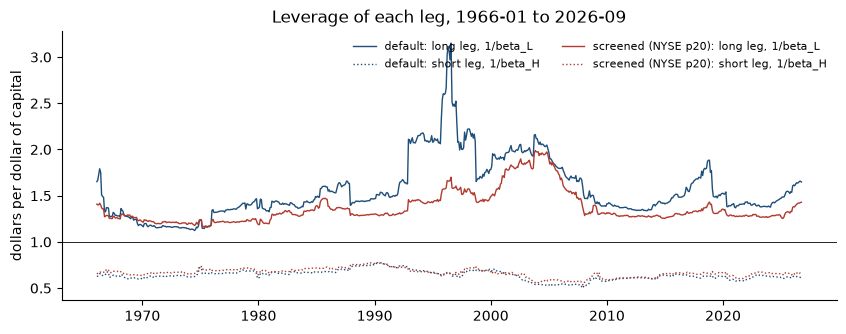

In [5]:
lev_cols = ["lev_L", "lev_H", "cash", "beta_L", "beta_H", "n_L", "n_H"]
lev_rows = {}
for name, b in books.items():
    for c in lev_cols:
        lev_rows[(name, c)] = {"median": b[c].median(), "min": b[c].min(), "min date": f"{b[c].idxmin():%Y-%m}",
                               "max": b[c].max(), "max date": f"{b[c].idxmax():%Y-%m}"}
print(f"Leverage, cash, ex-ante betas and counts, holding months {FULL}")
show(pd.DataFrame(lev_rows).T.rename_axis(["construction", "item"]), precision=2)

fig, ax = plt.subplots(figsize=(10, 3.5))
for (name, b), color in zip(books.items(), ["#1f4e79", "#b03a2e"]):
    ax.plot(b.index, b["lev_L"], color=color, lw=1, label=f"{name}: long leg, 1/beta_L")
    ax.plot(b.index, b["lev_H"], color=color, lw=1, ls=":", label=f"{name}: short leg, 1/beta_H")
ax.axhline(1, color="black", lw=0.6)
ax.set(title=f"Leverage of each leg, {FULL}", ylabel="dollars per dollar of capital")
ax.legend(frameon=False, fontsize=8, ncol=2); ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Ex-ante against realized leg betas (as in 3.3), 1966-01 to 2026-09.** The realized beta is the slope of each unlevered leg's excess return on `Mkt-RF`. "Levered realized" multiplies it by the leg's average leverage.

In [6]:
beta_rows = {}
for name, b in books.items():
    for leg, side in [("L", "long leg"), ("H", "short leg")]:
        real = realized_beta(b[f"r_{leg}"])
        beta_rows[(name, side)] = {"avg ex-ante beta": b[f"beta_{leg}"].mean(), "realized beta": real,
                                   "realized - ex-ante": real - b[f"beta_{leg}"].mean(),
                                   "avg leverage": b[f"lev_{leg}"].mean(),
                                   "levered realized beta": real * b[f"lev_{leg}"].mean()}
print(f"Leg betas, holding months {FULL}")
show(pd.DataFrame(beta_rows).T.rename_axis(["construction", "leg"]))

Leg betas, holding months 1966-01 to 2026-09


**Turnover and composition (the table of 3.4).** One-way turnover is $\sum_i |w_{i,t} - w^{\text{drift}}_{i,t-1}|$ on signed, levered weights, unhalved, averaged from the second formation month. Composition is the share of each leg's weight, at formation, in stocks below the NYSE 20th percentile of market cap and in stocks priced under $5. In the screened book the below-p20 share is zero by construction.

In [7]:
comp_cols = ["turnover", "small_L", "small_H", "penny_L", "penny_H"]
comp_names = ["one-way turnover / month", "long: below NYSE p20", "short: below NYSE p20",
              "long: price < $5", "short: price < $5"]
comp = pd.concat({name: pd.DataFrame({FULL: b[comp_cols].mean(), POST: b.loc["2014":, comp_cols].mean()}).T
                  for name, b in books.items()}, names=["construction", "period"])
comp.columns = comp_names
show(comp, pct=comp_names)

**From 2014: Sharpe ratio with standard error, alpha with t-statistic, realized beta.** Holding months 2014-01 to 2026-09 (153 months, 12.75 years).

In [8]:
post_cols = ["mean", "vol", "sharpe", "sharpe_se", "alpha", "t_alpha", "beta", "months"]
post = pd.concat({"1966-01 to 2026-09": perf_full.xs("book", level="series")[post_cols],
                  "2014-01 to 2026-09": perf_table(books, "2014-01").xs("book", level="series")[post_cols]},
                 names=["period", "construction"])
show(post, pct=["mean", "vol", "alpha"], precision=2)

### 4.3 What the screen changed


In [9]:
prem = 12 * mkt.reindex(book_def.index).mean()
d, s = perf_full.loc[("default", "book")], perf_full.loc[("screened (NYSE p20)", "book")]
split = pd.DataFrame({name: {"mean": p["mean"], "alpha": p["alpha"], "beta x premium": p["beta"] * prem}
                      for name, p in [("default", d), ("screened (NYSE p20)", s)]})
split["change"] = split["screened (NYSE p20)"] - split["default"]
print(f"Book mean excess return = alpha + beta x premium, {FULL}; market premium {prem:.2%} a year")
show(split, pct=split.columns)
print(f"Sharpe: {d['sharpe']:.2f} -> {s['sharpe']:.2f}, change {s['sharpe'] - d['sharpe']:+.2f} "
      f"= {(s['sharpe'] - d['sharpe']) / d['sharpe_se']:+.1f} standard errors of one book ")

Book mean excess return = alpha + beta x premium, 1966-01 to 2026-09; market premium 7.03% a year


,default,screened (NYSE p20),change
mean,8.75%,5.52%,-3.23%
alpha,7.37%,5.44%,-1.94%
beta x premium,1.38%,0.09%,-1.29%


Sharpe: 0.81 -> 0.54, change -0.27 = -2.1 standard errors of one book 


**Where the default's leftover beta comes from.** For each leg: average ex-ante beta → realized beta (gap in brackets), then average leverage → leverage × realized beta (the leg's realized market exposure). Net = long exposure − short exposure. This approximates the book's realized beta, shown alongside from the regression. Holding months 1966-01 to 2026-09.

In [10]:
gap_rows = {}
for name in books:
    row = {}
    for side, leg in [("Long", "long leg"), ("Short", "short leg")]:
        r = beta_rows[(name, leg)]
        row[f"{side} leg: ex-ante → realized"] = (f"{r['avg ex-ante beta']:.3f} → {r['realized beta']:.3f} "
                                                  f"({r['realized - ex-ante']:+.3f})")
        row[f"{side}: avg leverage → × realized beta"] = f"{r['avg leverage']:.3f} → {r['levered realized beta']:.2f}"
    net = beta_rows[(name, "long leg")]["levered realized beta"] - beta_rows[(name, "short leg")]["levered realized beta"]
    row["Net (long − short)"] = f"{net:+.2f}"
    row["Book realized beta (regression)"] = f"{perf_full.loc[(name, 'book'), 'beta']:.2f}"
    gap_rows[name] = row
display(pd.DataFrame(gap_rows).T.rename_axis("construction"))

,Long leg: ex-ante → realized,Long: avg leverage → × realized beta,Short leg: ex-ante → realized,Short: avg leverage → × realized beta,Net (long − short),Book realized beta (regression)
construction,,,,,,
default,0.663 → 0.769 (+0.106),1.563 → 1.20,1.570 → 1.489 (-0.081),0.641 → 0.95,+0.25,0.20
screened (NYSE p20),0.741 → 0.761 (+0.020),1.369 → 1.04,1.510 → 1.504 (-0.007),0.665 → 1.00,+0.04,0.01


**4.3.** The screen weakens the case for the baseline without overturning it. 

The largest change in the reported results is the fall in the book's mean excess return, from 8.75% to 5.52% a year, which takes the Sharpe ratio from 0.81 to 0.54, about two standard errors of either estimate. Splitting the mean shows that the two parts of the fall have different causes. About 1.9 points is lost alpha (7.37% to 5.44%, t from 5.47 to 4.08). This loss in alpha means that part of the low-beta premium lives in stocks below the NYSE 20th percentile. That part is the hardest to capture because of trading costs, large percentage trades, or moving the price from a transaction. In the default, more than half of each leg sits below that size cut, and ~ 21% and 29% of the legs are priced under $5. After the screen, those penny shares are 0.7% and 3.1%. 

The other 1.3 points is market exposure the default carried without intending to, as its realized beta falls from 0.20 to 0.01. That is measurement error. Small stocks have high residual volatility, so their 60-month betas are the noisiest. Sorting on them puts the most negative errors in the long leg and the most positive in the short leg (default book: long leg 0.66 ex-ante vs 0.77 realized, short leg 1.57 ex-ante vs 1.49 realized). The default's long leg realizes 0.11 more beta than its ex-ante estimate and its short leg 0.08 less, so levering the long leg to 1/β_L (median 1.45, peak 3.15) over-levers it. In the screened book these gaps shrink to 0.02 and −0.01, the ex-ante leg betas are less extreme (0.74 and 1.51 against 0.66 and 1.57), leverage peaks at 1.99, and the book is close to market-neutral (+0.04 net compared to +0.25) after the fact. 

Our 4.1 expectation held as stated: alpha and the Sharpe ratio fell, alpha stayed positive with t = 4.08 > 2, and turnover fell. But turnover fell only from 35.1% to 32.1% a month, so the screen improves capacity mainly by changing which names are traded, not how much. And we did not foresee that the measurement-error effect would show up mostly in the realized beta rather than in alpha. After the screen, the baseline's full-sample premium is smaller but still statistically significant (alpha 5.44%, t = 4.08) and better hedged (realized beta 0.01). From 2014 neither book's alpha is distinguishable from zero (t = 0.76 default, 1.15 screened; Sharpe standard error 0.28), so that period cannot rank them.

## 5. Risk

### 5.1 Pre-registration

Two pass/fail criteria an allocator would apply to this trade. **Each criterion applies to each construction separately: the default book and the NYSE-20th-percentile screened book of Section 4.** Both are graded in 7.1. They also bind the Section 6 work done on these books. This cell is the original declaration and is not edited. Any revision goes in a second dated cell below it.

1. **Full sample, after costs.** Pass if the book's Sharpe ratio over 1966-01 to 2026-09, net of the Section 6.1 **high trading-cost schedule** (one-way cost by NYSE size quintile at formation, 100/50/30/20/10 bp, applied to $\sum_i |w_{i,t} - w^{\text{drift}}_{i,t-1}|$; the 50 bp financing spread is reported separately and is not deducted here), is **at least 0.40**. 
Reason: the market's own Sharpe ratio over the same months is about 0.45. A hedged, levered overlay that cannot come close to it after trading costs does not earn its complexity. With a standard error of about 0.13, 0.40 is roughly three standard errors above zero. To be decided by: the 6.1 net Sharpe, full sample.

2. **Realized beta (implementation): down-market beta.** Pass if the book's beta over the months of 1966-01 to 2026-09 with Mkt-RF < 0 (OLS with intercept on that subset, as in 5.4; point estimate) is **at most 0.25**. 
Reason: the allocator buys this book as a hedged return, so it must not lose with the market when the market falls. A down-market beta above a quarter would mean the "zero-beta" book gives back a material share of each market decline. To be decided by: the 5.4 down-market beta.

### 5.2 Drawdowns

Wealth $W_t$ is the compounded path of the book's monthly excess return, starting at 1 in 1965-12. Drawdown is $W_t / \max_{s \le t} W_s - 1$. The **peak** is the last month at the running maximum before the trough. **Recovery** is the first later month in which $W_t$ regains the peak level. **Months under water** run from the peak to the recovery month, or to 2026-09 if not recovered (marked "not recovered"). The **market's cumulative excess return** is $\prod(1 + \text{Mkt-RF}) - 1$ over the months after the peak up to and including the trough. Holding months 1966-01 to 2026-09. Recovery and months under water come from `bx.drawdown_episodes`.

The five deepest episodes of each book are shown first for context.

In [11]:
episodes = {name: bx.drawdown_episodes(b["book"], mkt) for name, b in books.items()}


def fmt_episodes(ep):
    out = ep.copy()
    for c in ["peak", "trough"]:
        out[c] = out[c].dt.strftime("%Y-%m")
    out["recovery"] = [f"{r:%Y-%m}" if ok else "not recovered" for r, ok in zip(ep["recovery"], ep["recovered"])]
    out["book lost, market rose"] = ep["mkt_peak_to_trough"] > 0
    return out.drop(columns="recovered")


print(f"Five deepest drawdowns of each book (compounded excess-return path), holding months {FULL}")
show(pd.concat({name: fmt_episodes(ep.head(5)) for name, ep in episodes.items()}, names=["construction", "rank"]),
     pct=["depth", "mkt_peak_to_trough"])

Five deepest drawdowns of each book (compounded excess-return path), holding months 1966-01 to 2026-09


**The two episodes reported for each book.** Besides each book's largest drawdown, the contrast episode is the *other* book's largest one: the episode of this book whose span from peak to recovery contains the other book's deepest trough. The group chose this pairing so that both books are shown in the same two events. The 2007–09 crisis is a loss alongside a falling market. The 1998–2000 technology run-up is a loss while the market rose. Comparing them separates losses from leftover market beta from losses the hedge does not cover.

In [12]:
deepest_trough = {name: ep.loc[0, "trough"] for name, ep in episodes.items()}
chosen = {}
for name, ep in episodes.items():
    other = next(n for n in books if n != name)
    end = ep["recovery"].fillna(book_def.index[-1])
    contrast = ep[(ep["peak"] < deepest_trough[other]) & (end >= deepest_trough[other])].iloc[0]
    chosen[(name, "largest")] = ep.loc[0]
    chosen[(name, "contrast")] = contrast
chosen = pd.DataFrame(chosen).T.rename_axis(["construction", "episode"])
print(f"Selected drawdown episodes, holding months {FULL}")
show(fmt_episodes(chosen.astype({"depth": float, "mkt_peak_to_trough": float, "recovered": bool,
                                 "months_under_water": int}).assign(
                                     peak=lambda d: pd.to_datetime(d["peak"]),
                                     trough=lambda d: pd.to_datetime(d["trough"]),
                                     recovery=lambda d: pd.to_datetime(d["recovery"]))),
     pct=["depth", "mkt_peak_to_trough"])

Selected drawdown episodes, holding months 1966-01 to 2026-09


**Where each loss came from.** Over the months after the peak through the trough, the book's monthly excess return is exactly L_L·r_L − L_H·r_H. The sums of the two contributions therefore add up to the sum of the book's monthly returns; compounded returns are shown alongside. Leverage and ex-ante betas are averages over the same months.

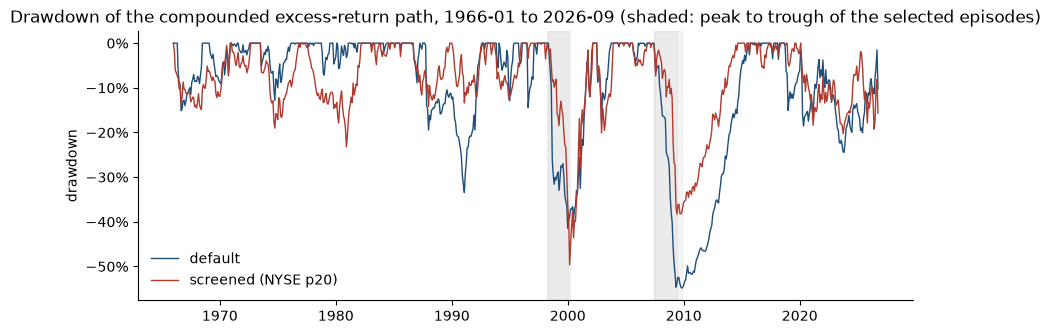

In [13]:
decomp = pd.DataFrame({key: bx.episode_decomposition(books[key[0]], mkt, row["peak"], row["trough"])
                       for key, row in chosen.iterrows()})
decomp.columns = pd.MultiIndex.from_tuples(
    [(n, f"{e}: {chosen.loc[(n, e), 'peak']:%Y-%m} to {chosen.loc[(n, e), 'trough']:%Y-%m}") for n, e in decomp.columns])
pct_rows = [r for r in decomp.index if r.startswith(("sum", "compounded"))]
display(decomp.style.format("{:.2%}", subset=pd.IndexSlice[pct_rows, :])
        .format("{:.2f}", subset=pd.IndexSlice[[r for r in decomp.index if r not in pct_rows], :]))

fig, ax = plt.subplots(figsize=(10, 3.5))
for (name, b), color in zip(books.items(), ["#1f4e79", "#b03a2e"]):
    w = bx.wealth_path(b["book"])
    ax.plot(w.index, w / w.cummax() - 1, color=color, lw=1, label=name)
for name, e in chosen.index:
    r = chosen.loc[(name, e)]
    ax.axvspan(r["peak"], r["trough"], color="grey", alpha=0.08)
ax.set(title=f"Drawdown of the compounded excess-return path, {FULL} (shaded: peak to trough of the selected episodes)",
       ylabel="drawdown")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Inside the 2007–09 episodes.** Each crisis episode is split at the market's own low within it, the month in which the compounded Mkt-RF path is lowest. This separates the crash from the rebound.

In [14]:
split_rows = {}
for name, e in [("default", "largest"), ("screened (NYSE p20)", "contrast")]:
    r = chosen.loc[(name, e)]
    m_path = (1 + mkt.loc[r["peak"]:r["trough"]].iloc[1:]).cumprod()
    m_low = m_path.idxmin()
    after_low = book_def.index[book_def.index.get_loc(m_low) + 1]
    for part, (a, z) in {f"peak to market low {m_low:%Y-%m}": (r["peak"], m_low),
                         f"{after_low:%Y-%m} to trough {r['trough']:%Y-%m}": (m_low, r["trough"])}.items():
        split_rows[(name, part)] = bx.episode_decomposition(books[name], mkt, a, z)
split_tab = pd.DataFrame(split_rows).T.rename_axis(["construction", "sub-period"])
keep = ["months", "avg lev_L", "avg lev_H", "sum long contribution L_L*r_L", "sum short contribution -L_H*r_H",
        "compounded book", "compounded r_L (unlevered)", "compounded r_H (unlevered)", "compounded Mkt-RF"]
show(split_tab[keep], pct=keep[3:], precision=2)

**5.2. Episodes.** Default book: its largest drawdown runs from 2007-05 to 2009-10 (−54.9%), recovers in 2015-07 after 98 months, and the market's excess return over it is −30.3%. Its contrast runs from 1998-04 to 1999-12 (−41.4%), recovers in 2002-02 after 46 months, with the market at +25.5%. Screened book: its largest runs from 1998-03 to 2000-02 (−49.6%), recovers in 2002-02 after 47 months, with the market at +23.4%. Its contrast runs from 2007-05 to 2009-05 (−38.3%), recovers in 2014-08 after 87 months, with the market at −38.6%. The screen reverses the ranking: it makes the crisis loss shallower (−54.9% to −38.3%) and the technology-bubble loss deeper (−41.4% to −49.6%).

**Losing while the market rose.** Both books lost in 1998–2000 while the market rose, and the five-deepest tables add the default's still-open drawdown from 2018-08 (−24.4%, market +38.9%) and the screened book's 1977-04 (−23.2%, market +40.5%) and 2020-01 (−20.3%, market +32.1%) episodes. In 1998–2000 both legs lost. The unlevered high-beta leg rose 25.4% (default) and 60.0% (screened), costing the short side 22.0 and 39.1 points (summed monthly contributions). Meanwhile the low-beta leg fell 12.1% and 17.4%, and, levered at 1.81 and 1.47, cost another 28.3 and 26.1 points. The cause is the construction itself. Hedged to zero ex-ante beta, the book is still a levered bet that low-beta stocks beat high-beta stocks per unit of beta, so it loses whenever high-beta stocks outrun their betas, whatever the market does. The screened book loses more overall because its short leg, large high-beta stocks, rose 60.0% and cost 39.1 points, against 25.4% and 22.0 points in the default.

**Losing with the market (2007–09).** The default's crisis loss has a different source. From the 2007-05 peak to the market's low in 2009-02, its long leg fell 57.1% unlevered, more than the market's 51.4%, against an average ex-ante beta of 0.67 over the episode. Levered at 1.53, the long leg cost 120.8 points, while the short gained 55.5. Then, from 2009-03 to 2009-10, the high-beta leg rebounded 137.8% and cost the short side 58.4 points. The loss came from leftover bet`a on the way down and from the short leg on the way up. The screened book had the same pattern but smaller: −26.8% in the crash and −15.7% in a three-month rebound to its 2009-05 trough.

### 5.3 Rolling beta and tail risk

The rolling beta is the OLS slope of the book's monthly excess return on Mkt-RF over the trailing 36 months, so the first value is dated 1968-12. Holding months 1966-01 to 2026-09.

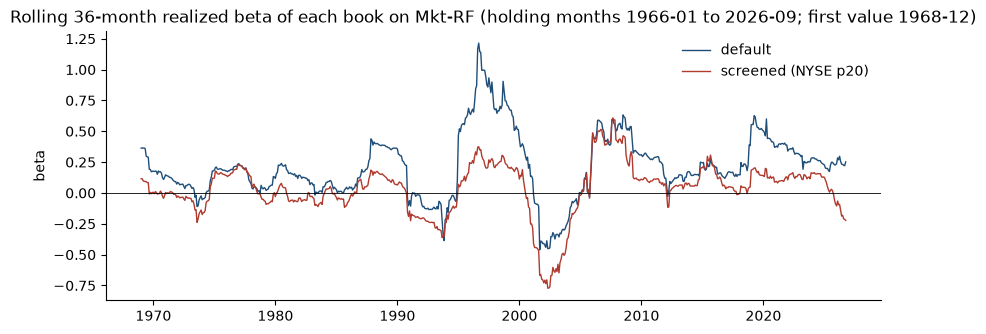

,min,min date,max,max date,median,share of windows > 0.25,windows
default,-0.46,2001-08,1.21,1996-08,0.18,36.74%,694
screened (NYSE p20),-0.77,2002-04,0.61,2007-08,0.06,9.22%,694


In [15]:
roll = pd.DataFrame({name: bx.rolling_beta_series(b["book"], mkt, 36) for name, b in books.items()})

fig, ax = plt.subplots(figsize=(10, 3.5))
for (name, s), color in zip(roll.items(), ["#1f4e79", "#b03a2e"]):
    ax.plot(s.index, s, color=color, lw=1, label=name)
ax.axhline(0, color="black", lw=0.6)
ax.set(title=f"Rolling 36-month realized beta of each book on Mkt-RF (holding months {FULL}; first value 1968-12)",
       ylabel="beta")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.show()

roll_summary = pd.DataFrame({name: {"min": s.min(), "min date": f"{s.idxmin():%Y-%m}",
                                    "max": s.max(), "max date": f"{s.idxmax():%Y-%m}",
                                    "median": s.median(), "share of windows > 0.25": (s.dropna() > 0.25).mean(),
                                    "windows": int(s.notna().sum())}
                             for name, s in roll.items()}).T
show(roll_summary, pct=["share of windows > 0.25"], precision=2)

**Tail risk.** Monthly 5% VaR and CVaR of the book's excess return over all 729 holding months, 1966-01 to 2026-09. **VaR and CVaR are shown as returns, so a loss is negative.** Historical VaR is the 5th percentile of the monthly returns (linear interpolation). CVaR is the mean of the returns at or below it. Normal VaR is the monthly mean − 1.645 × the monthly standard deviation. Skewness and excess kurtosis are pandas `.skew()` and `.kurt()`, and normal kurtosis is 0.

In [16]:
tails = pd.DataFrame({name: bx.tail_risk(b["book"]) for name, b in books.items()}).T
tails["months"] = tails["months"].astype(int)
print(f"Monthly tail risk of the book's excess return, {FULL}")
show(tails, pct=["hist_VaR_5%", "hist_CVaR_5%", "normal_VaR_5%"], precision=2)

Monthly tail risk of the book's excess return, 1966-01 to 2026-09


,hist_VaR_5%,hist_CVaR_5%,normal_VaR_5%,skew,excess_kurtosis,months
default,-4.48%,-7.20%,-4.43%,-0.50,5.20,729
screened (NYSE p20),-4.16%,-6.80%,-4.43%,-0.49,4.04,729


**5.3.** The default book's 36-month beta ranges from −0.46 (window ending 2001-08) to 1.21 (window ending 1996-08), with a median of 0.18, and is above 0.25 in 36.7% of windows. Its maximum coincides with the long leg's peak leverage of 3.15 in 1996-07 (4.2). The screened book's beta ranges from −0.77 (2002-04) to 0.61 (2007-08), with a median of 0.06, and is above 0.25 in only 9.2% of windows. Neither book is zero-beta window by window. Both minima come in windows ending in 2001–02, which span the technology bubble and its collapse. The screen centres the beta near zero but does not remove the swings; its minimum is lower than the default's. In the tails, the monthly 5% historical VaR is −4.48% (default) and −4.16% (screened). The normal VaR is −4.43% for both, so at the 5% quantile the normal approximation is close. Beyond that quantile it is not: CVaR is −7.20% and −6.80%, skewness −0.50 and −0.49, and excess kurtosis 5.20 and 4.04. Losses beyond the 5% VaR are larger than a normal distribution implies, a little less so for the screened book.

### 5.4 Up- and down-market betas

The book's beta is estimated separately over months with Mkt-RF > 0 and months with Mkt-RF < 0, by OLS with an intercept on each subset, with plain OLS t-statistics. Alpha is annualized. Holding months 1966-01 to 2026-09.

In [ ]:
updown = pd.concat({name: bx.up_down_beta(b["book"], mkt) for name, b in books.items()},
                   names=["construction", "months"])
updown["months"] = updown["months"].astype(int)
full_beta = perf_full.xs("book", level="series")["beta"]
print(f"Months with Mkt-RF exactly 0 (in neither group): {int((mkt.reindex(book_def.index) == 0).sum())}")
print("single realized beta: " + ", ".join(f"{n} {b:.2f}" for n, b in full_beta.items()))
show(updown, pct=["alpha_ann"], precision=2)

Months with Mkt-RF exactly 0 (in neither group): 0
single realized beta (3.2): default 0.20, screened (NYSE p20) 0.01


**5.4.** The default book's beta is −0.09 (t = −1.67, 433 months) when the market rises and 0.49 (t = 8.85, 296 months) when it falls. For the screened book the figures are −0.09 (t = −1.61) and 0.13 (t = 2.43). The single realized betas (0.20 default book and 0.01 screened book) average two different exposures. Neither book gains when the market rises, but the default loses about half of each market decline, so its market risk is one-sided, like a short put. That is the exposure that hurt it in 2007–09. The screen cuts the down-market beta from 0.49 to 0.13, though it remains significantly above zero. (5.1 criterion 2 is decided on these down-market betas and is applied in 7.1.)

## Export: the two books for Sections 6 and 7

Both books are rebuilt from one function, `bab_extra.make_books(panel)`, which uses exactly the arguments used above. The first cell checks that it reproduces this notebook's books. The second writes them to `Project_Beta/output/`:

- `book_default.csv`, `book_screened.csv`: one row per holding month, 1966-01 to 2026-09, with the `build_book` columns (`beta_L, beta_H, lev_L, lev_H, cash, n_L, n_H, r_L, r_H, book, rf, turnover, small_L, small_H, penny_L, penny_H, failed`).
- `weights_default.parquet`, `weights_screened.parquet`: signed levered weights by formation date and permno, for the Section 6 cost calculation (turnover by NYSE size quintile).

```python
import bab_extra as bx
panel = bx.load_panel()
books = bx.make_books(panel)          # {"default": (book, weights), "screened": (book, weights)}
```

**For Sections 6–7.** The 5.1 criteria above bind the Section 6 work on these books. Criterion 1 is the full-sample Sharpe net of the high trading-cost schedule (≥ 0.40). Criterion 2 is the 5.4 down-market beta (≤ 0.25), already computed above. Both apply to each book separately.

In [18]:
recipe = bx.make_books(panel)
for key, (b, w) in [("default", (book_def, w_def)), ("screened", (book_scr, w_scr))]:
    rb, rw = recipe[key]
    pd.testing.assert_frame_equal(rb, b)
    pd.testing.assert_frame_equal(rw, w)
print("bx.make_books reproduces both books and their weights exactly")

bx.make_books reproduces both books and their weights exactly


In [19]:
out_dir = bx.DATA_DIR.parent / "output"
out_dir.mkdir(exist_ok=True)
for key, (b, w) in recipe.items():
    b.to_csv(out_dir / f"book_{key}.csv", date_format="%Y-%m-%d")
    w.to_parquet(out_dir / f"weights_{key}.parquet", index=False)
    print(f"{key}: {len(b)} holding months ({b.index[0]:%Y-%m} to {b.index[-1]:%Y-%m}), "
          f"{len(w):,} weight rows -> output/book_{key}.csv, output/weights_{key}.parquet")

reloaded = pd.read_csv(out_dir / "book_screened.csv", index_col="date", parse_dates=True)
print(f"round-trip check, screened book return: max abs difference "
      f"{(reloaded['book'] - recipe['screened'][0]['book']).abs().max():.1e}")

default: 729 holding months (1966-01 to 2026-09), 2,616,498 weight rows -> output/book_default.csv, output/weights_default.parquet
screened: 729 holding months (1966-01 to 2026-09), 1,179,014 weight rows -> output/book_screened.csv, output/weights_screened.parquet
round-trip check, screened book return: max abs difference 9.9e-17


## Citations

AI Citations: Claude Opus 5.5 (Anthropic), through Claude Code, was used to assist with the code (`bab_extra.py` and this notebook) and with the analysis and writing for Sections 4 and 5. The group chose the Section 4 mechanism, the 4.1 expectation, the 5.1 criteria and thresholds, and the 5.2 contrast episodes. Every number in the text comes from the executed cells above.